# Cookie Cats A/B Test: Does Moving the First Gate Help Retention?

**Cookie Cats** is a mobile puzzle game by Tactile Entertainment. Players occasionally hit *gates* that make them wait
(or pay) before continuing. In this experiment, new players were randomly assigned to one of two versions:

| Group | Version | First gate at |
|---|---|---|
| Control (A) | `gate_30` | level 30 |
| Treatment (B) | `gate_40` | level 40 |

**Questions**
1. Did the average number of game rounds increase by **at least 5 rounds**?
2. Did 1-day retention increase by **at least 2 percentage points**?
3. Did 7-day retention increase by **at least 5 percentage points**?

Throughout, "2%" and "5%" are read as **absolute percentage points** (e.g. 44.8% → 46.8%), not relative changes.

**Design:** significance level α = 0.05, target power 1 − β = 0.80.

## 1. Setup and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ALPHA = 0.05
POWER = 0.80
RNG = np.random.default_rng(42)

df = pd.read_csv("cookie_cats.txt")
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.2 MB


## 2. Data checks

**Duplicates and missing values.** Each player must appear exactly once.

In [3]:
print("Duplicate user IDs:", df["userid"].duplicated().sum())
print("Missing values:", int(df.isna().sum().sum()))

Duplicate user IDs: 0
Missing values: 0


**Sample ratio mismatch (SRM).** Players were meant to be split 50/50. A chi-square goodness-of-fit test checks
whether the observed split is consistent with that. A failed SRM check would mean the randomisation is broken and the
results can't be trusted.

In [4]:
counts = df["version"].value_counts().sort_index()
srm = stats.chisquare(counts)
print(counts.to_string())
print(f"\nShare in gate_40: {counts['gate_40'] / counts.sum():.2%}")
print(f"SRM chi-square p-value: {srm.pvalue:.3f}")

version
gate_30    44700
gate_40    45489

Share in gate_40: 50.44%
SRM chi-square p-value: 0.009


The split is 49.6% / 50.4%. With 90,189 players even this small imbalance gives a low p-value (≈ 0.009), so it
is worth noting. The imbalance is about 0.4 percentage points, which is too small to explain the retention
differences below, so we proceed but flag it as a limitation.

**Outliers.** We do **not** remove outliers with the IQR rule: that would drop the ~10,000 most engaged players, who
are exactly the players most likely to come back, and would bias the retention comparison. We only check for
impossible values.

In [5]:
df["sum_gamerounds"].describe()

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

In [6]:
df.nlargest(3, "sum_gamerounds")

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False


One player logged **49,854 rounds in 14 days** (about 3,500 rounds a day). That is not plausible and is treated as a
data error. It is excluded **from the game-rounds analysis only**; it doesn't affect retention, which is a yes/no flag.

Players in rounds analysis: 90,188 (excluded 1)


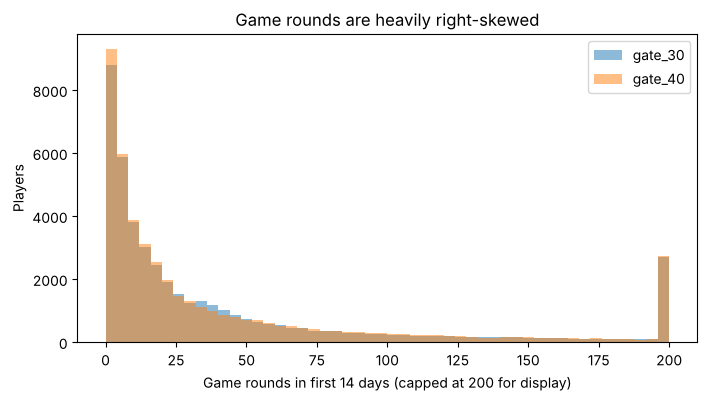

In [7]:
rounds = df[df["sum_gamerounds"] < 10_000]
print(f"Players in rounds analysis: {len(rounds):,} (excluded {len(df) - len(rounds)})")

fig, ax = plt.subplots(figsize=(8, 4))
for v, color in [("gate_30", "tab:blue"), ("gate_40", "tab:orange")]:
    ax.hist(rounds.loc[rounds.version == v, "sum_gamerounds"].clip(upper=200), bins=50,
            alpha=0.5, label=v, color=color)
ax.set_xlabel("Game rounds in first 14 days (capped at 200 for display)")
ax.set_ylabel("Players")
ax.set_title("Game rounds are heavily right-skewed")
ax.legend()
plt.show()

## 3. Power: what can this experiment detect?

A power analysis is a *planning* tool: it says how many players you need. Here the data is already collected, so we
use **all** players and instead ask the reverse question: *with this many players, what is the smallest effect we
could reliably detect?* (minimum detectable effect, MDE).

For a difference in proportions with baseline rate p and n players per group:

$$\text{MDE} \approx \left(z_{1-\alpha/2} + z_{1-\beta}\right)\sqrt{\frac{2\,p(1-p)}{n}}$$

In [8]:
z = stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(POWER)
n_per_group = counts.min()

for metric in ["retention_1", "retention_7"]:
    p = df.loc[df.version == "gate_30", metric].mean()
    mde = z * np.sqrt(2 * p * (1 - p) / n_per_group)
    print(f"{metric}: baseline {p:.2%}, MDE ≈ {mde * 100:.2f} percentage points")

sd = rounds["sum_gamerounds"].std()
print(f"sum_gamerounds: MDE ≈ {z * sd * np.sqrt(2 / n_per_group):.2f} rounds")

retention_1: baseline 44.82%, MDE ≈ 0.93 percentage points
retention_7: baseline 19.02%, MDE ≈ 0.74 percentage points
sum_gamerounds: MDE ≈ 1.92 rounds


The experiment can detect effects far smaller than the 2-, 5-point and 5-round targets, so if those effects
existed we would very likely see them.

## 4. Helper functions

In [9]:
def compare_proportions(data, metric, target):
    # Compare a yes/no metric between gate_40 and gate_30.
    # Returns the difference, a 95% CI, a two-sided test of 'any difference',
    # and a one-sided test of H0: p40 - p30 <= target  vs  H1: p40 - p30 > target.
    a = data.loc[data.version == "gate_30", metric]
    b = data.loc[data.version == "gate_40", metric]
    p_a, p_b, n_a, n_b = a.mean(), b.mean(), len(a), len(b)
    diff = p_b - p_a

    # Two-sided test of no difference (pooled standard error)
    p_pool = (a.sum() + b.sum()) / (n_a + n_b)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
    p_any = 2 * stats.norm.sf(abs(diff / se_pool))

    # Unpooled standard error for the CI and the test against a non-zero target
    se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    ci = (diff - 1.96 * se, diff + 1.96 * se)
    p_target = stats.norm.sf((diff - target) / se)

    return pd.Series({
        "gate_30": p_a, "gate_40": p_b, "difference (pp)": diff * 100,
        "95% CI low (pp)": ci[0] * 100, "95% CI high (pp)": ci[1] * 100,
        "p (any difference)": p_any, f"p (increase > {target * 100:.0f} pp)": p_target,
    })


def bootstrap_diff(data, metric, stat=np.mean, n_boot=5_000):
    # Bootstrap distribution of stat(gate_40) - stat(gate_30).
    a = data.loc[data.version == "gate_30", metric].to_numpy()
    b = data.loc[data.version == "gate_40", metric].to_numpy()
    out = np.empty(n_boot)
    for i in range(n_boot):
        out[i] = stat(RNG.choice(b, b.size)) - stat(RNG.choice(a, a.size))
    return out

## 5. Question 1: Did average game rounds increase by at least 5?

- H₀: μ₄₀ − μ₃₀ ≤ 5
- H₁: μ₄₀ − μ₃₀ > 5

Game rounds are heavily skewed, so instead of relying on a t-test we bootstrap the difference in means (no
normality assumption) and add a Mann–Whitney U test as a rank-based check for *any* shift.

In [10]:
g = rounds.groupby("version")["sum_gamerounds"]
print(g.agg(["count", "mean", "median"]).round(2).to_string())

boot_rounds = bootstrap_diff(rounds, "sum_gamerounds")
diff_rounds = g.mean()["gate_40"] - g.mean()["gate_30"]
ci_rounds = np.percentile(boot_rounds, [2.5, 97.5])
p_rounds_target = (boot_rounds > 5).mean()

mw = stats.mannwhitneyu(rounds.loc[rounds.version == "gate_30", "sum_gamerounds"],
                        rounds.loc[rounds.version == "gate_40", "sum_gamerounds"])

print(f"\nDifference in means (gate_40 − gate_30): {diff_rounds:.2f} rounds")
print(f"95% bootstrap CI: [{ci_rounds[0]:.2f}, {ci_rounds[1]:.2f}]")
print(f"Share of bootstrap samples with an increase > 5 rounds: {p_rounds_target:.4f}")
print(f"Mann–Whitney U p-value (any shift): {mw.pvalue:.3f}")

         count   mean  median
version                      
gate_30  44699  51.34    17.0
gate_40  45489  51.30    16.0



Difference in means (gate_40 − gate_30): -0.04 rounds
95% bootstrap CI: [-1.34, 1.33]
Share of bootstrap samples with an increase > 5 rounds: 0.0000
Mann–Whitney U p-value (any shift): 0.051


**Result:** the means are practically identical (difference ≈ 0 rounds, 95% CI roughly −1.3 to +1.3), and none of
the bootstrap samples shows an increase of 5 rounds. **Game rounds did not increase by 5.** The Mann–Whitney test
(p ≈ 0.05) hints at a very small shift in the distribution, which is borderline and not practically meaningful.

## 6. Question 2: Did 1-day retention increase by at least 2 percentage points?

- H₀: p₄₀ − p₃₀ ≤ 0.02
- H₁: p₄₀ − p₃₀ > 0.02

We also test the broader question of whether there is *any* difference (two-sided).

In [11]:
r1 = compare_proportions(df, "retention_1", target=0.02)
r1.round(4)

gate_30                0.4482
gate_40                0.4423
difference (pp)       -0.5905
95% CI low (pp)       -1.2393
95% CI high (pp)       0.0582
p (any difference)     0.0744
p (increase > 2 pp)    1.0000
dtype: float64

**Result:** 1-day retention is about 0.6 points *lower* with the gate at level 40. The two-sided p-value is ≈ 0.07,
so the drop is not statistically significant at α = 0.05, and an increase of 2 points is clearly ruled out.

## 7. Question 3: Did 7-day retention increase by at least 5 percentage points?

- H₀: p₄₀ − p₃₀ ≤ 0.05
- H₁: p₄₀ − p₃₀ > 0.05

In [12]:
r7 = compare_proportions(df, "retention_7", target=0.05)
r7.round(4)

gate_30                0.1902
gate_40                0.1820
difference (pp)       -0.8201
95% CI low (pp)       -1.3282
95% CI high (pp)      -0.3121
p (any difference)     0.0016
p (increase > 5 pp)    1.0000
dtype: float64

**Result:** 7-day retention **fell** from 19.0% to 18.2% (−0.8 points, 95% CI roughly −1.3 to −0.3 points). The
two-sided p-value is ≈ 0.002, so this decrease **is** statistically significant. A 5-point increase is ruled out.

## 8. Bootstrap check of the retention results

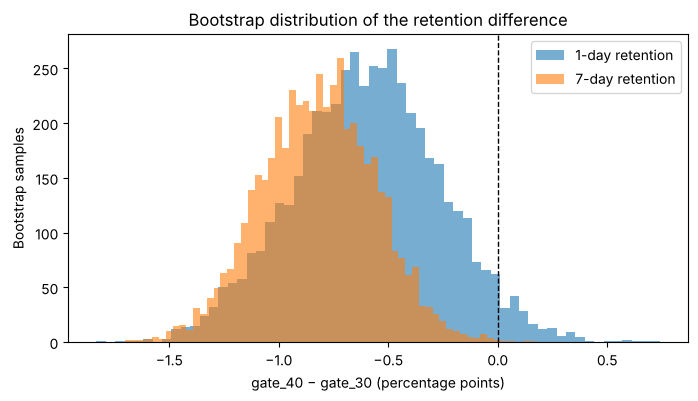

1-day: 95% CI [-1.26, 0.06] pp, P(gate_40 better) = 0.036
7-day: 95% CI [-1.33, -0.33] pp, P(gate_40 better) = 0.001


In [13]:
boot_r1 = bootstrap_diff(df, "retention_1") * 100
boot_r7 = bootstrap_diff(df, "retention_7") * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(boot_r1, bins=60, alpha=0.6, label="1-day retention")
ax.hist(boot_r7, bins=60, alpha=0.6, label="7-day retention")
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("gate_40 − gate_30 (percentage points)")
ax.set_ylabel("Bootstrap samples")
ax.set_title("Bootstrap distribution of the retention difference")
ax.legend()
plt.show()

for name, b in [("1-day", boot_r1), ("7-day", boot_r7)]:
    print(f"{name}: 95% CI [{np.percentile(b, 2.5):.2f}, {np.percentile(b, 97.5):.2f}] pp, "
          f"P(gate_40 better) = {(b > 0).mean():.3f}")

The bootstrap agrees with the z-tests: the 7-day distribution lies almost entirely below zero, while the 1-day
distribution overlaps zero slightly.

## 9. Summary

In [14]:
summary = pd.DataFrame({
    "Metric": ["Game rounds (mean)", "1-day retention", "7-day retention"],
    "gate_30": [f"{g.mean()['gate_30']:.1f}", f"{r1['gate_30']:.1%}", f"{r7['gate_30']:.1%}"],
    "gate_40": [f"{g.mean()['gate_40']:.1f}", f"{r1['gate_40']:.1%}", f"{r7['gate_40']:.1%}"],
    "Difference": [f"{diff_rounds:+.2f} rounds", f"{r1['difference (pp)']:+.2f} pp", f"{r7['difference (pp)']:+.2f} pp"],
    "Target reached?": ["No (+5 rounds)", "No (+2 pp)", "No (+5 pp)"],
    "p (any difference)": [f"{mw.pvalue:.3f}", f"{r1['p (any difference)']:.3f}", f"{r7['p (any difference)']:.4f}"],
})
summary

,Metric,gate_30,gate_40,Difference,Target reached?,p (any difference)
0,Game rounds (mean),51.3,51.3,-0.04 rounds,No (+5 rounds),0.051
1,1-day retention,44.8%,44.2%,-0.59 pp,No (+2 pp),0.074
2,7-day retention,19.0%,18.2%,-0.82 pp,No (+5 pp),0.0016


### Conclusion and recommendation

- None of the three targets was reached.
- Moving the gate to level 40 **significantly lowered 7-day retention** (19.0% → 18.2%, p ≈ 0.002). 1-day retention
  dropped slightly but not significantly, and game rounds were essentially unchanged.
- **Recommendation: keep the first gate at level 30.** A plausible explanation is that the earlier gate gives players
  a forced break sooner, which keeps the game from becoming tiresome and brings them back over the following week.

### Limitations

- The 50/50 split is very slightly off (49.6% / 50.4%, SRM p ≈ 0.009). The imbalance is small, but in practice it
  should be investigated with the engineering team before relying on the result.
- Retention is measured only at day 1 and day 7; long-term retention and in-app revenue are not in the data.
- Three questions are tested on the same experiment. The significant 7-day result (p ≈ 0.002) survives a Bonferroni
  correction (0.05 / 3 ≈ 0.017).